In the age of social media, product reviews, and customer feedback, understanding people's opinions has become more important than ever. Sentiment analysis is a powerful natural language processing (NLP) technique that allows us to determine whether a piece of text expresses a positive, negative, or neutral sentiment. This technique is widely used in areas such as customer feedback analysis, brand reputation management, and social media monitoring.

We will build a deep learning-based sentiment analysis model using TensorFlow. We will cover:

✅ The fundamentals of sentiment analysis and its real-world applications

✅ Preprocessing text data for machine learning models

✅ Training a neural network to classify text as positive or negative

✅ Evaluating model performance and improving accuracy

Let’s get started! 🚀



# 📂 Importing Libraries  

Before we begin, let's import the necessary libraries. TensorFlow will be used for building and training our text classification model, while other libraries will help with data preprocessing and evaluation.  


In [8]:
! pip install pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 6.4 MB/s eta 0:00:0000:010:01

[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [9]:
import matplotlib.pyplot as plt
import os
import re
import shutil
import string
import tensorflow as tf

import pandas as pd

from tensorflow.keras import layers
from tensorflow.keras import losses

print(tf.__version__)


2.21.0


# 🎭 Sentiment Analysis  

This notebook trains a **sentiment analysis model** to classify movie reviews as **positive or negative**, based on the text of the review. This is an example of **binary classification**.  

We will use the **Large Movie Review Dataset**, which contains **50,000 movie reviews** from the Internet Movie Database (IMDB).


## 📥 Load the Dataset  


Load the data off disk and prepare it into a format suitable for training.  




In [10]:
df = pd.read_csv("IMDB Dataset.csv")




Next, you will use the **`text_dataset_from_directory`** utility to create a **labeled** `tf.data.Dataset`. The **`tf.data`** module provides a powerful collection of tools for efficiently loading and processing data for machine learning tasks.  

When running a machine learning experiment, it is a **best practice** to divide the dataset into three splits:  

- **Training Set (Train)** → Used to train the model  
- **Validation Set (Validation)** → Used to fine-tune hyperparameters and prevent overfitting  
- **Test Set (Test)** → Used to evaluate the final model performance  

The **IMDB dataset** is already divided into **train** and **test** sets, but it lacks a **validation set**. To create a validation set, we will perform an **80:20 split** of the training data using the **`validation_split`** argument in `text_dataset_from_directory`.  


In [31]:
batch_size = 32
seed = 42

shuffled_df = df.sample(frac=1, random_state=seed).reset_index(drop=True)

texts = shuffled_df["review"].astype(str).to_numpy(dtype=str)
labels = (
    shuffled_df["sentiment"].str.strip().str.lower() == "positive"
).astype("int32").to_numpy()

n = len(shuffled_df)
train_end = int(0.8 * n)   # 80 % train
val_end = int(0.9 * n)     # 10 % validation, 10 % test

def make_ds(start, end):
    return tf.data.Dataset.from_tensor_slices(
        (texts[start:end], labels[start:end])
    ).batch(batch_size)

raw_train_ds = make_ds(0, train_end)
raw_val_ds = make_ds(train_end, val_end)
raw_test_ds = make_ds(val_end, n)

In [32]:
for text_batch, label_batch in raw_train_ds.take(1):
  for i in range(3):
    print("Review", text_batch.numpy()[i])
    print("Label", label_batch.numpy()[i])

Review b"I really liked this Summerslam due to the look of the arena, the curtains and just the look overall was interesting to me for some reason. Anyways, this could have been one of the best Summerslam's ever if the WWF didn't have Lex Luger in the main event against Yokozuna, now for it's time it was ok to have a huge fat man vs a strong man but I'm glad times have changed. It was a terrible main event just like every match Luger is in is terrible. Other matches on the card were Razor Ramon vs Ted Dibiase, Steiner Brothers vs Heavenly Bodies, Shawn Michaels vs Curt Hening, this was the event where Shawn named his big monster of a body guard Diesel, IRS vs 1-2-3 Kid, Bret Hart first takes on Doink then takes on Jerry Lawler and stuff with the Harts and Lawler was always very interesting, then Ludvig Borga destroyed Marty Jannetty, Undertaker took on Giant Gonzalez in another terrible match, The Smoking Gunns and Tatanka took on Bam Bam Bigelow and the Headshrinkers, and Yokozuna def


Notice that the **reviews contain raw text**, including:  

- **Punctuation**  
- **Occasional HTML tags** (e.g., `<br/>`)  

You will learn how to **handle and preprocess** these in the following section.  

The labels in this dataset are **0 or 1**, representing binary sentiment classification. To determine which label corresponds to **positive or negative reviews**, you can check the `class_names` property of the dataset.  


## 🛠 Prepare the Dataset for Training  

Before training the model, we need to **standardize, tokenize, and vectorize** the text data. This will be done using the **`tf.keras.layers.TextVectorization`** layer.  

### 🔹 Key Preprocessing Steps  

1. **Standardization** → Preprocesses text by removing unnecessary elements (e.g., punctuation, HTML tags) to simplify the dataset.  
2. **Tokenization** → Splits text into individual words or tokens (e.g., splitting on whitespace).  
3. **Vectorization** → Converts tokens into numerical representations so they can be fed into a neural network.  

The **default standardizer** in the `TextVectorization` layer automatically:  
✅ Converts text to **lowercase**  
✅ **Strips punctuation**  

However, it **does not remove HTML tags** like `<br />`, which are present in the dataset. To handle this, you will write a **custom standardization function** to remove HTML elements before processing the text.  


In [33]:
def custom_standardization(input_data):
  lowercase = tf.strings.lower(input_data)
  stripped_html = tf.strings.regex_replace(lowercase, '<br />', ' ')
  return tf.strings.regex_replace(stripped_html,
                                  '[%s]' % re.escape(string.punctuation),
                                  '')

🔠 Creating the `TextVectorization` Layer  

Next, you will create a **`TextVectorization`** layer to **standardize, tokenize, and vectorize** the dataset. This layer will help transform raw text into a format suitable for training a deep learning model.  

### 🔹 Key Configurations  

- **`output_mode="int"`** → Converts tokens into unique integer indices.  
- **Custom standardization function** → Removes HTML tags (defined earlier).  
- **Default split function** → Splits text into words based on whitespace.  
- **`sequence_length`** → Defines a fixed length for input sequences, ensuring consistency by **padding** or **truncating** reviews to this length.  

By applying these transformations, you will prepare the dataset for efficient model training. 🚀  


In [34]:
max_features = 10000
sequence_length = 250

vectorize_layer = layers.TextVectorization(
    standardize=custom_standardization,
    max_tokens=max_features,
    output_mode='int',
    output_sequence_length=sequence_length)


Next, you will call **`adapt`** to fit the state of the **preprocessing layer** to the dataset. This step allows the model to **build an index of unique words**, mapping each word to a **corresponding integer value**.  

This process ensures that the model learns a **consistent vocabulary**, which is essential for transforming text into numerical representations that a neural network can process.  


In [35]:
# Make a text-only dataset (without labels), then call adapt
train_text = raw_train_ds.map(lambda x, y: x)
vectorize_layer.adapt(train_text)

Let's create a function to see the result of using this layer to preprocess some data

In [36]:
def vectorize_text(text, label):
  text = tf.expand_dims(text, -1)
  return vectorize_layer(text), label

In [37]:
# retrieve a batch (of 32 reviews and labels) from the dataset
text_batch, label_batch = next(iter(raw_train_ds))
first_review, first_label = text_batch[0], label_batch[0]
print("Review", first_review)
# The dataset was created with integer labels, so map them explicitly
# instead of using the unavailable dataset.class_names attribute.
print("Label", "positive" if int(first_label.numpy()) == 1 else "negative")
print("Vectorized review", vectorize_text(first_review, first_label))

Review tf.Tensor(b"I really liked this Summerslam due to the look of the arena, the curtains and just the look overall was interesting to me for some reason. Anyways, this could have been one of the best Summerslam's ever if the WWF didn't have Lex Luger in the main event against Yokozuna, now for it's time it was ok to have a huge fat man vs a strong man but I'm glad times have changed. It was a terrible main event just like every match Luger is in is terrible. Other matches on the card were Razor Ramon vs Ted Dibiase, Steiner Brothers vs Heavenly Bodies, Shawn Michaels vs Curt Hening, this was the event where Shawn named his big monster of a body guard Diesel, IRS vs 1-2-3 Kid, Bret Hart first takes on Doink then takes on Jerry Lawler and stuff with the Harts and Lawler was always very interesting, then Ludvig Borga destroyed Marty Jannetty, Undertaker took on Giant Gonzalez in another terrible match, The Smoking Gunns and Tatanka took on Bam Bam Bigelow and the Headshrinkers, and Yo

 🔢 Mapping Tokens to Vocabulary  

As you can see above, each **token** has been replaced by an **integer**.  

You can look up the **corresponding token (string)** for each integer by calling **`.get_vocabulary()`** on the `TextVectorization` layer.  


In [38]:
print("1287 ---> ",vectorize_layer.get_vocabulary()[1287])
print(" 313 ---> ",vectorize_layer.get_vocabulary()[313])
print('Vocabulary size: {}'.format(len(vectorize_layer.get_vocabulary())))

1287 --->  frank
 313 --->  idea
Vocabulary size: 10000



You are nearly ready to **train your model**!  

As a final preprocessing step, you will apply the **`TextVectorization`** layer you created earlier to the **train, validation, and test datasets**.  


In [39]:
train_ds = raw_train_ds.map(vectorize_text)
val_ds = raw_val_ds.map(vectorize_text)
test_ds = raw_test_ds.map(vectorize_text)

## 🏗️ Create the Model  

It's time to **build your neural network**! 🚀  


In [40]:
embedding_dim = 16

In [ ]:
model = tf.keras.Sequential([
  layers.Embedding(max_features, embedding_dim),
  layers.Dropout(0.2),
  layers.GlobalAveragePooling1D(),
  layers.Dropout(0.2),
  layers.Dense(128, activation = 'relu' ),
  layers.Dense(128, activation = 'relu' ),
  layers.Dense(1, activation='sigmoid')])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_1      │ ?                      │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

## 🏗️ Model Architecture  

The layers are **stacked sequentially** to build the sentiment classification model:  

### 🔹 **Embedding Layer**  
- Converts **integer-encoded reviews** into **dense vector representations**.  
- These **embedding vectors** are **learned during training**.  
- The output shape: **(batch, sequence, embedding)**.  
- To learn more, check out the [Word Embeddings Tutorial](https://www.tensorflow.org/tutorials/text/word_embeddings).  

### 🔹 **GlobalAveragePooling1D Layer**  
- Computes a **fixed-length output vector** for each input example.  
- **Averages** over the sequence dimension, allowing the model to handle **variable-length inputs**.  

### 🔹 **Dense Output Layer**  
- Fully connected layer with **a single output node**.  
- This node predicts the **sentiment polarity** (positive or negative).  


## ⚙️ Loss Function and Optimizer  

A model needs a **loss function** and an **optimizer** for training.  

Since this is a **binary classification** problem and the model outputs a **probability** (a single-unit layer with a **sigmoid activation**), you will use:  

- **Loss Function:** `losses.BinaryCrossentropy()` → Suitable for binary classification problems.  
- **Optimizer:** You will configure the model to use an **optimizer** along with the loss function to enable learning.  


In [42]:
model.compile(loss=losses.BinaryCrossentropy(),
              optimizer='adam',
              metrics=[tf.metrics.BinaryAccuracy(threshold=0.5)])

## 🚀 Train the Model  

You will train the model by passing the **dataset object** to the `fit` method.  


In [43]:
epochs = 10
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=epochs)

Epoch 1/10


/Users/amonbazongo/.pyenv/versions/3.13.0/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1250/1250 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - binary_accuracy: 0.6933 - loss: 0.6138 - val_binary_accuracy: 0.7994 - val_loss: 0.5108
Epoch 2/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - binary_accuracy: 0.8310 - loss: 0.4317 - val_binary_accuracy: 0.8462 - val_loss: 0.3939
Epoch 3/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - binary_accuracy: 0.8625 - loss: 0.3492 - val_binary_accuracy: 0.8598 - val_loss: 0.3494
Epoch 4/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - binary_accuracy: 0.8786 - loss: 0.3075 - val_binary_accuracy: 0.8668 - val_loss: 0.3268
Epoch 5/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - binary_accuracy: 0.8899 - loss: 0.2802 - val_binary_accuracy: 0.8688 - val_loss: 0.3153
Epoch 6/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - binary_accuracy: 0.8979 - loss: 0.2620 - val_binary_accuracy: 0.8702 - val_loss: 0.3112
Epoch 7/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - binary_accuracy: 0.9034 - loss: 0.2463 - val_binary_accuracy: 0.8758 - val_loss: 0.3033
Epo

## 📊 Evaluate the Model  

Let's see how the model performs.  

The evaluation will return **two key metrics**:  
- **Loss** → Represents the model’s error (**lower is better**).  
- **Accuracy** → Measures the percentage of correct predictions.  


In [44]:
loss, accuracy = model.evaluate(test_ds)

print("Loss: ", loss)
print("Accuracy: ", accuracy)

157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - binary_accuracy: 0.8876 - loss: 0.2803
Loss:  0.2803090214729309
Accuracy:  0.8876000046730042


## 📈 Plot Accuracy and Loss Over Time  

The `model.fit()` method returns a **History** object that contains a dictionary with all the details of the training process.  

You can use this data to **visualize the accuracy and loss** over time, helping to analyze model performance.  


In [45]:
history_dict = history.history
history_dict.keys()

dict_keys(['binary_accuracy', 'loss', 'val_binary_accuracy', 'val_loss'])

## 📊 Visualizing Training and Validation Metrics  

The `History` object contains **four entries**, representing the **monitored metrics** during training and validation:  

- **Training Loss**  
- **Validation Loss**  
- **Training Accuracy**  
- **Validation Accuracy**  

You can use these metrics to **compare training and validation performance** by plotting:  
✅ Training vs. Validation Loss  
✅ Training vs. Validation Accuracy  

This helps in identifying potential **overfitting** or **underfitting** issues. 📉📈  


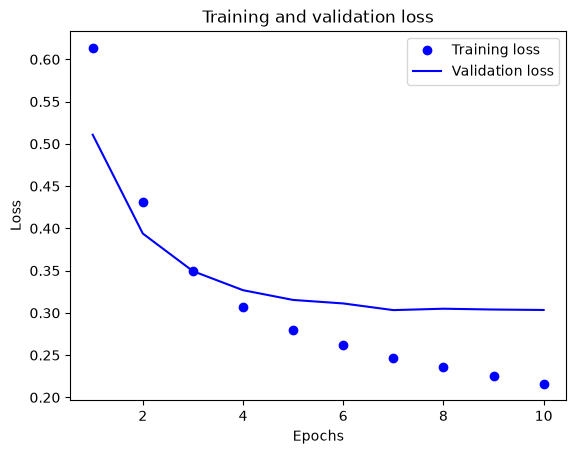

In [ ]:
acc = history_dict['binary_accuracy']
val_acc = history_dict['val_binary_accuracy']
loss = history_dict['loss']
val_loss = history_dict['val_loss']

epochs = range(1, len(acc) + 1)

# "bo" is for "blue dot"
plt.plot(epochs, loss, 'bo', label='Training loss')
# b is for "solid blue line"
plt.plot(epochs, val_loss, 'b', label='Validation loss')
plt.title('Training and validation loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.show()

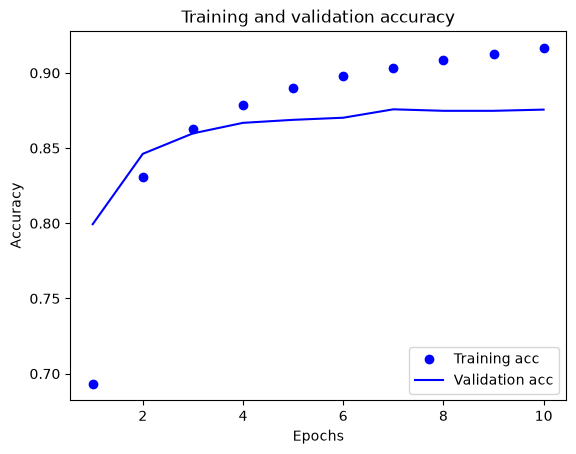

In [47]:
plt.plot(epochs, acc, 'bo', label='Training acc')
plt.plot(epochs, val_acc, 'b', label='Validation acc')
plt.title('Training and validation accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')

plt.show()

## 📉 Understanding the Training and Validation Curves  

In the plot:  
- **Dots** represent the **training loss** and **accuracy**.  
- **Solid lines** represent the **validation loss** and **accuracy**.  

### 🔹 Observations  
✅ **Training loss decreases** and **training accuracy increases** with each epoch.  
✅ This is expected, as **gradient descent optimization** minimizes the loss over time.  

However, the **validation loss and accuracy behave differently**:  
⚠️ They **peak before training accuracy** and then start **decreasing or fluctuating**.  
⚠️ This is a classic sign of **overfitting** → The model performs well on training data but struggles with unseen data.  

### 🛠 Preventing Overfitting  
One effective way to **prevent overfitting** is to **stop training** when validation accuracy is no longer improving.  

A simple way to implement this is by using:  
🔹 **`tf.keras.callbacks.EarlyStopping`** → Automatically stops training when validation performance starts to degrade.  


# 📦 Export the Model  

In the code above, the **`TextVectorization`** layer was applied to the dataset **before** feeding text into the model.  

If you want to make your model capable of processing **raw text inputs directly** (which is useful for deployment), you can **embed the `TextVectorization` layer inside the model**.  

To achieve this, you will:  
✅ Create a **new model** using the **trained weights**.  
✅ Include the **TextVectorization** layer within the model architecture.  

This will allow the model to **process raw text inputs** without needing separate preprocessing steps. 🚀  


In [48]:
export_model = tf.keras.Sequential([
  vectorize_layer,
  model,
  layers.Activation('sigmoid')
])

export_model.compile(
    loss=losses.BinaryCrossentropy(from_logits=False), optimizer="adam", metrics=['accuracy']
)

# Test it with `raw_test_ds`, which yields raw strings
metrics = export_model.evaluate(raw_test_ds, return_dict=True)
print(metrics)

157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.5050 - loss: 0.5738
{'accuracy': 0.5049999952316284, 'loss': 0.5738210082054138}


## 🔍 Inference on New Data  

To make predictions on **new text inputs**, you can simply call:  


In [ ]:
examples = tf.constant([
  "The movie was great!",
  "The movie was okay.",
  "The movie was terrible..."
])

export_model.predict(examples)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step


array([[0.69058955],
       [0.647091  ],
       [0.6106874 ]], dtype=float32)

## 🚀 Deployment Considerations: Embedding Text Preprocessing in the Model  

Including the **text preprocessing logic** inside your model allows you to:  
✅ **Export a production-ready model** with built-in preprocessing.  
✅ **Simplify deployment** by ensuring raw text can be processed directly.  
✅ **Reduce train/test skew**, preventing discrepancies between training and inference time preprocessing.  

### ⚡ Performance Considerations  

🔹 **Applying `TextVectorization` Outside the Model**  
- Best for **GPU training** → Allows **asynchronous CPU processing and buffering**.  
- Improves **training performance** by offloading preprocessing.  

🔹 **Embedding `TextVectorization` Inside the Model**  
- Best for **deployment** → Ensures the model can handle **raw text inputs** directly.  
- Prevents the need for separate preprocessing during inference.  

For optimal **development workflow**:  
1️⃣ Use **external `TextVectorization`** during training for **better GPU efficiency**.  
2️⃣ Embed **`TextVectorization` inside the model** before deployment for **seamless inference**. 🚀  


# 🎉 Thank You for Following Along!  

You’ve successfully built a **sentiment analysis model** using **TensorFlow**! 🚀  


Happy coding! 😊  
